In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem1
import optimiser_new
from math import factorial
import pickle

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
sigma_s = 1e-1
b2 = 1e-3
a1 = -2

params = {'a0': 0, 'a1': a1, 'a2': 0, 'b0': 0, 'b1': 1, 'b2': b2,
              'sigma_alpha': 1, 'sigma_alpha_0': 0, 'sigma_s': sigma_s, 'k': 1e-3, 
              'theta1': 1, 'theta2': 1e-2, 'alpha0': 0, 'S0': 100, 'Q0': 10, 'X0': 0, 
              'T': 0.10, 'Nt': 1_000}

env_baseline = problem1.environment(**params)

In [3]:
np.random.seed(123)

nsims = 100

env_baseline.simulate(nsims, env_baseline.optimal_strag)

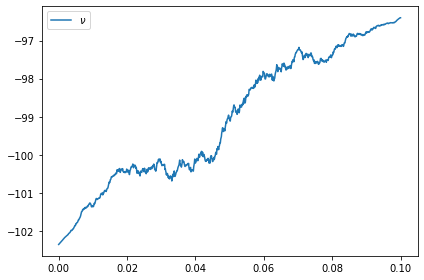

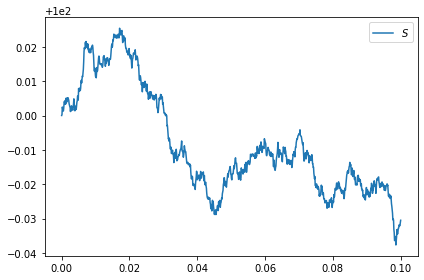

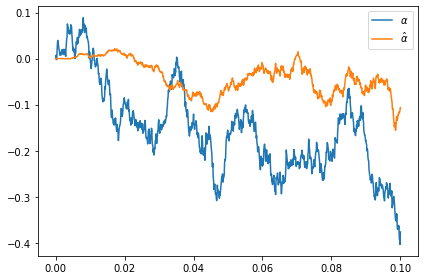

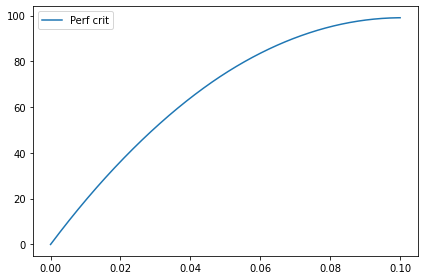

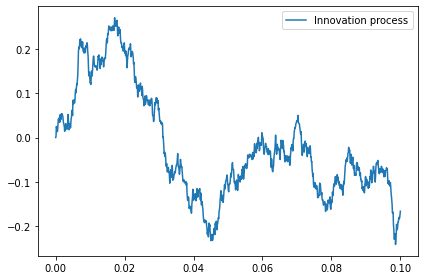

In [4]:
nsim = 2

plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env_baseline.timesteps, env_baseline.S[:,nsim], label=r'$S$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env_baseline.timesteps, env_baseline.alpha[:,nsim], label=r'$\alpha$')
plt.plot(env_baseline.timesteps, env_baseline.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env_baseline.timesteps, env_baseline.run_crit[:,nsim], label=r'Perf crit')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env_baseline.timesteps, env_baseline.innov[:,nsim], label=r'Innovation process')
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
np.random.seed(456)
dim = 2
order = 6
poly_deg = 5

with open('W_sig_1.pkl', 'rb') as f:
    W_sig = pickle.load(f)
    f.close()

with open('F_optimised_1.pkl', 'rb') as f:
    F = pickle.load(f)
    f.close()
    
env = problem1.environment(**params)
optimiser_1 = optimiser_new.Optimiser(env, W_sig, order = order, poly_deg = poly_deg)
F = ta.sig_to_tensor(F, optimiser_1.dim, optimiser_1.order)

In [6]:
optimiser_1.F = F

In [7]:
env_baseline.run_crit[-1,:].mean()

99.02442661410831

In [8]:
np.random.seed(456)
trunc_lev = 4
trunc_lev_1 = 4
n_epochs = 20
lr = 100

#optimiser_1.train_sgd(n_epochs, lr = lr, trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1, method='SGD')

#F = optimiser_1.F

strag_sig = problem1.sig_strag_dot(F, order = order)

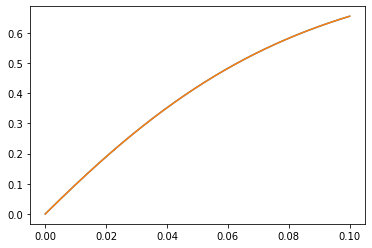

In [9]:
sigma_alpha_hat = env.b1*env.V_alpha/env.sigma_s
p_coef = np.polyfit(env.timesteps, sigma_alpha_hat, deg = poly_deg)
sigma_alpha_hat_fit = np.polyval(p_coef, env.timesteps)
plt.plot(env.timesteps, sigma_alpha_hat)
plt.plot(env.timesteps, sigma_alpha_hat_fit)

In [10]:
factorials = np.array([factorial(i) for i in range(poly_deg + 1)])

p_coef_reversed = p_coef[::-1]*factorials

In [11]:
p_coef[::-1]

array([ 2.40855190e-05,  9.98824000e+00, -1.86358933e+01, -3.71053680e+02,
        2.78024659e+03, -6.36462186e+03])

In [12]:
f_s = ta.word((),dim)*env.alpha0 + F*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
# word = (1,)
# for k in range(len(p_coef_reversed)):
#     word_tensor = ta.word(word,dim)
#     f_s += word_tensor*p_coef_reversed[k]
#     word = (0,) + word
f_s += optimiser_1.vol_sig
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev)
f_s = f_s*exp_a1
f_s = f_s*(ta.word((0,),dim)*env.b1)
f_s += ta.word((1,),dim)*env.sigma_s
f_s += ta.word((0,),dim)*env.b0
f_s += (F + optimiser_1.e0*env.Q0)*(ta.word((0,),dim)*env.b2)
f_s += ta.word((),dim)*env.S0 
f_s = f_s.truncate(trunc_lev)

f_alpha = ta.word((),dim)*env.alpha0 + (F + optimiser_1.e0*env.Q0)*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
word = (1,)
# for k in range(len(p_coef_reversed)):
#     word_tensor = ta.word(word,dim)
#     f_alpha += word_tensor*p_coef_reversed[k]
#     word = (0,) + word
f_alpha += optimiser_1.vol_sig
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev_1)
f_alpha = f_alpha*exp_a1
f_alpha = f_alpha.truncate(trunc_lev_1)

M_max = F.order
#M_max = 2*F.order
p_perf = -F.shuffle(F, max_order = M_max)
p_perf = p_perf*(optimiser_1.e1*optimiser_1.env.k)
#M_max = (F*optimiser_1.e1).order + F.order
p_perf += ((F*optimiser_1.e1 + optimiser_1.e0*env.Q0).shuffle(F, max_order = M_max))*(optimiser_1.e1*(optimiser_1.env.b2 - 2*optimiser_1.env.theta1))
#M_max = (F*optimiser_1.e1).order + trunc_lev_1
p_perf += ((F*optimiser_1.e1 + optimiser_1.e0*env.Q0).shuffle(f_alpha, max_order = M_max))*(optimiser_1.e1*optimiser_1.env.b1)
p_perf += ((F*optimiser_1.e1 + optimiser_1.e0*env.Q0)*(optimiser_1.e1*optimiser_1.env.b0))
F_prod_e1 = F*optimiser_1.e1
#M_max = 2*F_prod_e1.order
p_perf -= (F_prod_e1.shuffle(F_prod_e1, max_order = M_max) + F_prod_e1*optimiser_1.e0*env.Q0 + optimiser_1.e0*F_prod_e1*env.Q0 + optimiser_1.e0*env.Q0**2)*(optimiser_1.e1*optimiser_1.env.theta2)
p_perf = p_perf.truncate(optimiser_1.order)

In [13]:
np.random.seed(123)

nsims = 100

env.simulate(nsims, strag_sig)

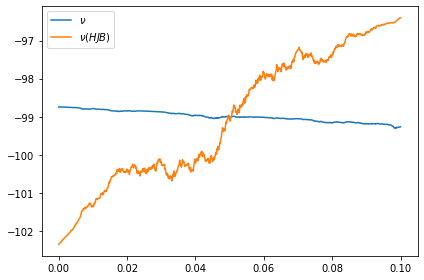

In [14]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
print(f'Performance criterion\nSig: {env.run_crit[-1,:].mean()}, HJB: {env_baseline.run_crit[-1,:].mean()}')
print(f'Wealth\nSig: {env.wealth[-1,:].mean()}, HJB: {env_baseline.wealth[-1,:].mean()}')

Performance criterion
Sig: 99.02407016019004, HJB: 99.02442661410831
Wealth
Sig: 998.9936802636297, HJB: 998.9933128323255


In [16]:
optimiser_1.value_fn(F.flatten(), trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1)

-98.92617907757138

In [17]:
# f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

f_s_sig = problem1.sig_strag_dot(f_s, order = trunc_lev)
f_alpha_sig = problem1.sig_strag_dot(f_alpha, order = trunc_lev_1)
f_perf_crit = problem1.sig_strag_dot(p_perf, order = order)

S_sig = np.zeros((env.Nt+1,nsims))
alpha_hat_sig = np.zeros((env.Nt+1,nsims))
perf_hist = np.zeros((env.Nt+1,nsims))

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(env.Nt+1):
    S_sig[it,:] = f_s_sig(env,it)
    alpha_hat_sig[it,:] = f_alpha_sig(env,it)
    perf_hist[it,:] = f_perf_crit(env,it)
    #S_sig[it,:] = strag_sig(env,it)

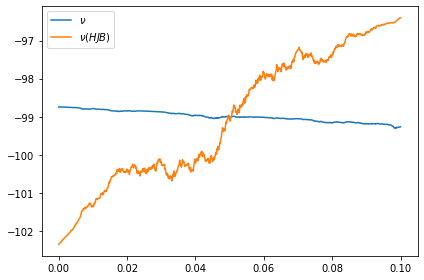

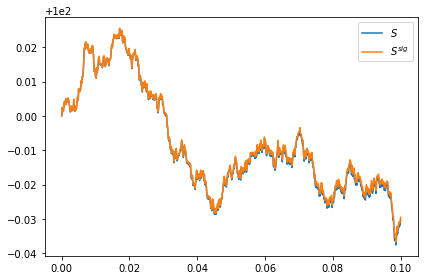

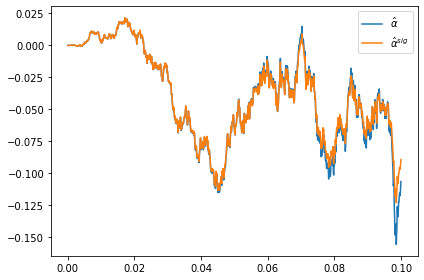

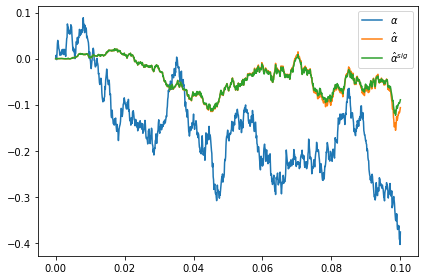

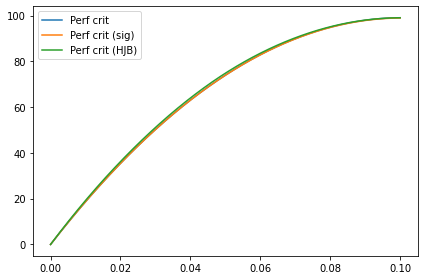

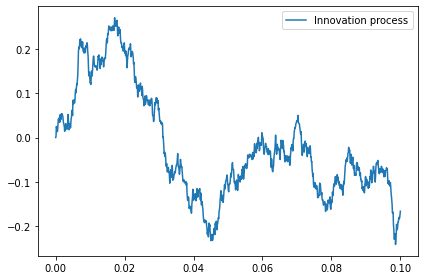

In [23]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.plot(env.timesteps, S_sig[:,nsim], label=r'$S^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps[:], alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha[:,nsim], label=r'$\alpha$')
plt.plot(env.timesteps, env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps, alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:,nsim], label=r'Perf crit (sig)')
plt.plot(env_baseline.timesteps[:], env_baseline.run_crit[:,nsim], label=r'Perf crit (HJB)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.innov[:,nsim], label=r'Innovation process')
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
for i in range(10,0,-1):
    print(i)

10
9
8
7
6
5
4
3
2
1
